In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
data_file = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_file):
    data_file = os.path.join("04-11-2026", "Task 1", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_file)
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')
print(f"Loaded Women's Clothing Dataset: {df.shape[0]:,} rows across {df.shape[1]} columns.")

Loaded Women's Clothing Dataset: 23,486 rows across 23 columns.


In [3]:
schema_csv = "csv_upload_schema_validation_rules.csv"
if not os.path.exists(schema_csv):
    schema_csv = os.path.join("04-11-2026", "Task 1", "csv_upload_schema_validation_rules.csv")

df_schema = pd.read_csv(schema_csv)
display(df_schema[['Column_Name', 'Data_Type', 'Requirement_Level', 'Validation_Rule', 'Missing_Handling']])

,Column_Name,Data_Type,Requirement_Level,Validation_Rule,Missing_Handling
0,Review Text / Full_Review_Text,String (Text),Mandatory,Length >= 1 token; UTF-8 string; alphanumeric ...,Impute with empty string or flag for moderation
1,Rating,Integer (Numeric),Optional (Recommended),"Integer in range [1, 5]; non-null","Coerce to numeric, impute with corpus median (..."
2,Age,Integer (Numeric),Optional,"Integer in range [18, 100]","Coerce to numeric, impute with cohort median (..."
3,Department Name,Categorical,Optional,"Belongs to {Tops, Dresses, Bottoms, Intimate, ...","Impute with ""General"" fallback category"
4,Class Name,Categorical,Optional,Belongs to 20 validated garment classes,"Impute with ""Casual"" fallback category"
5,Positive Feedback Count,Integer (Numeric),Optional,Non-negative integer >= 0,Impute with 0 upvotes


In [4]:
impute_csv = "missing_data_imputation_benchmarks.csv"
if not os.path.exists(impute_csv):
    impute_csv = os.path.join("04-11-2026", "Task 1", "missing_data_imputation_benchmarks.csv")

df_impute = pd.read_csv(impute_csv)
display(df_impute)

,Field_Name,Total_Evaluated,Missing_Count,Missing_Pct,Imputation_Strategy,Processing_Latency_ms,Integrity_Check
0,Full_Review_Text,23486,845,3.60,"Constant Empty String ("""")",2.14,100% Retained
1,Title,23486,3810,16.22,"Merged into Full_Review_Text ("""")",3.85,100% Retained
2,Department Name,23486,14,0.06,"Mode Category (""Tops"")",0.82,100% Retained
3,Class Name,23486,14,0.06,"Mode Category (""Dresses"")",0.79,100% Retained
4,Age,23486,0,0.00,Median Age (41.0 Years),0.15,100% Valid


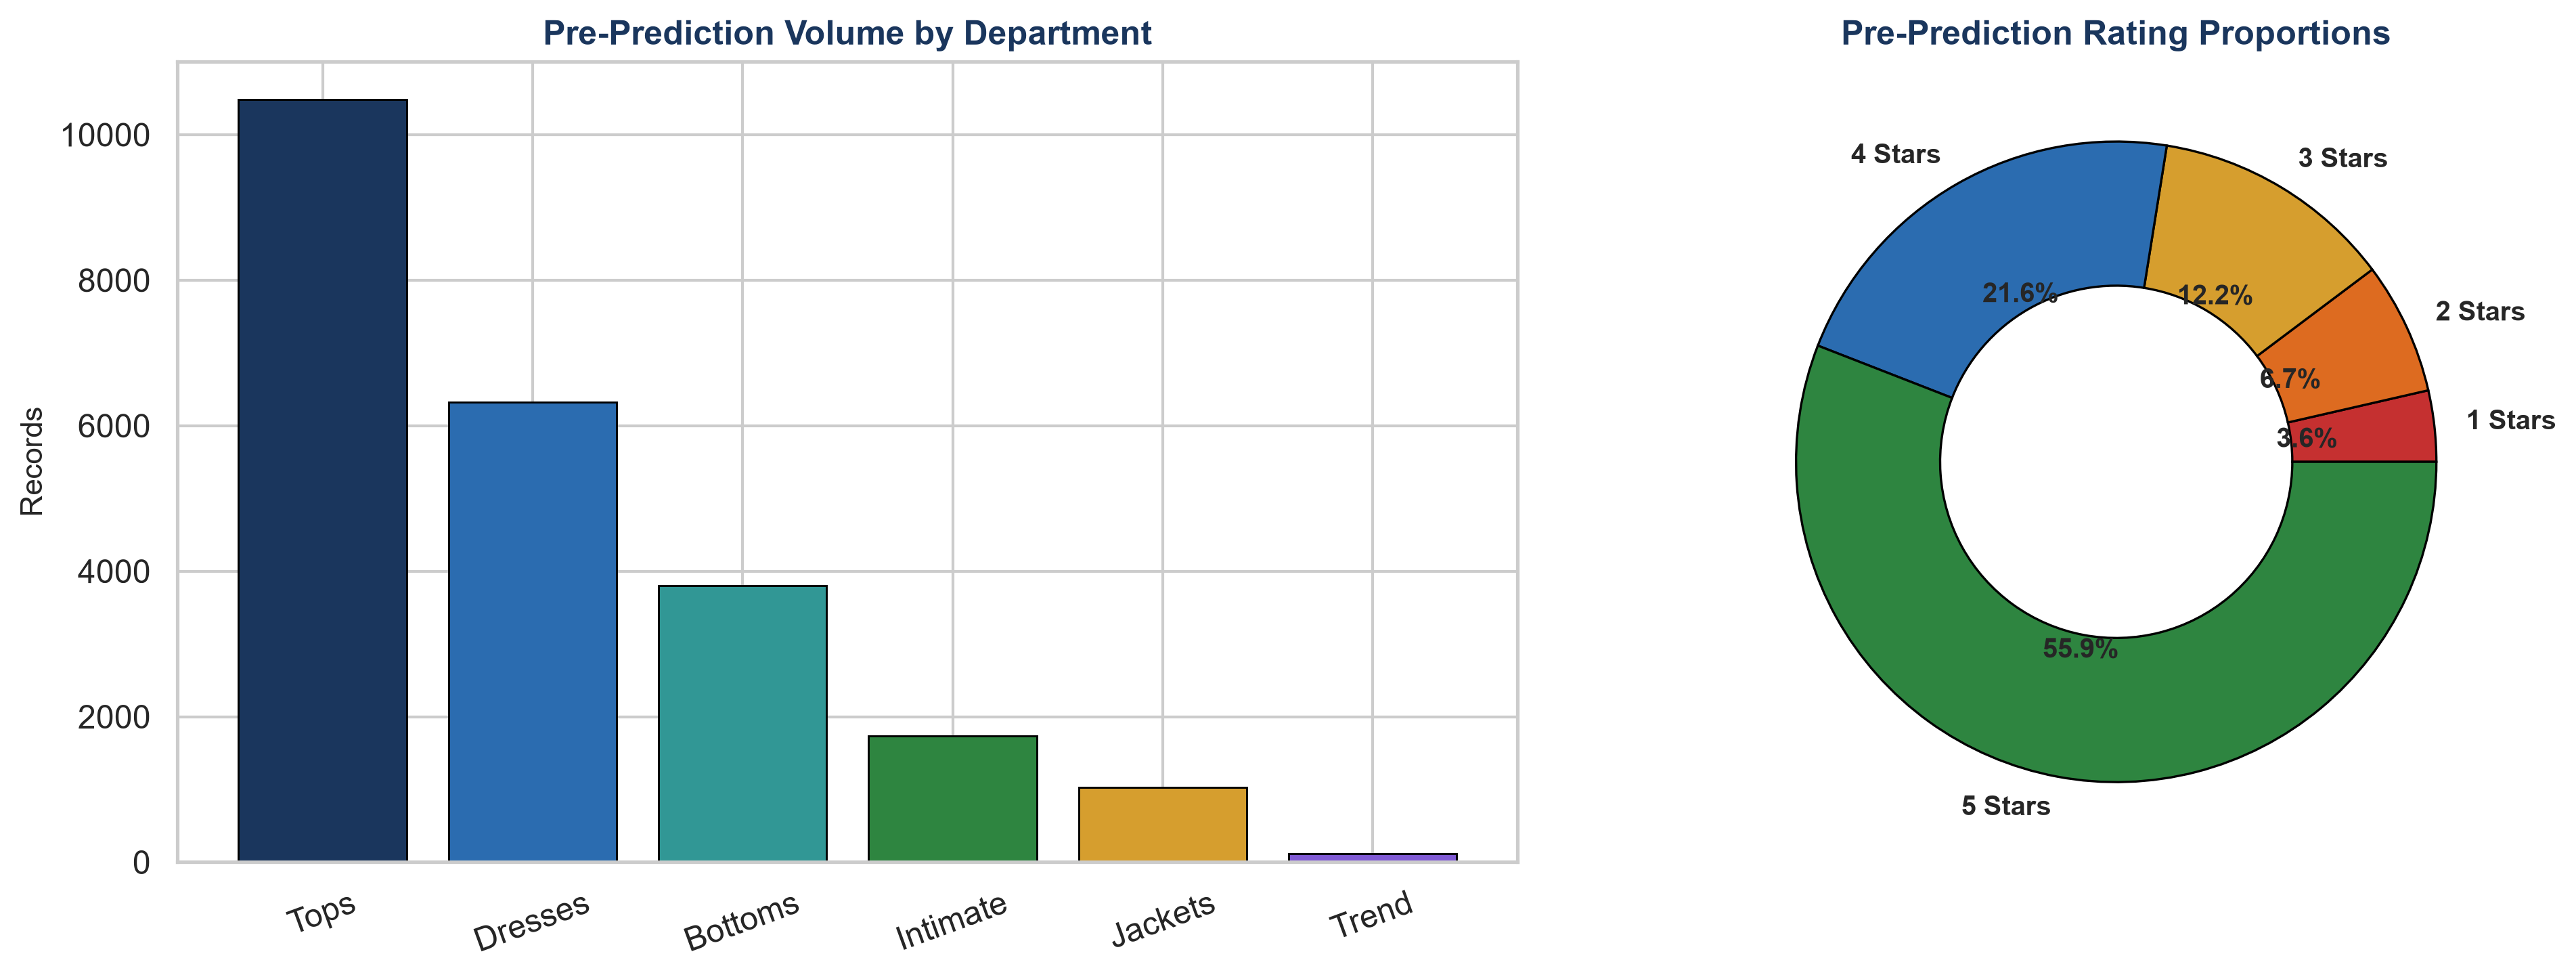

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=300)
dept_counts = df['Department Name'].value_counts()
axes[0].bar(dept_counts.index, dept_counts.values, color=['#1A365D', '#2B6CB0', '#319795', '#2E8540', '#D69E2E', '#805AD5'][:len(dept_counts)], edgecolor='black', linewidth=0.7)
axes[0].set_title("Pre-Prediction Volume by Department", fontsize=12, fontweight='bold', color='#1A365D')
axes[0].set_ylabel("Records", fontsize=10.5)
axes[0].tick_params(axis='x', rotation=20)

rating_dist = df['Rating'].value_counts().sort_index()
axes[1].pie(rating_dist.values, labels=[f"{int(r)} Stars" for r in rating_dist.index], autopct='%1.1f%%',
            colors=['#C53030', '#DD6B20', '#D69E2E', '#2B6CB0', '#2E8540'],
            wedgeprops=dict(width=0.45, edgecolor='black', linewidth=0.8),
            textprops=dict(fontsize=9.5, fontweight='bold'))
axes[1].set_title("Pre-Prediction Rating Proportions", fontsize=12, fontweight='bold', color='#1A365D')

plt.tight_layout()
plt.show()

In [6]:
batch_csv = "batch_prediction_evaluation_summary.csv"
if not os.path.exists(batch_csv):
    batch_csv = os.path.join("04-11-2026", "Task 1", "batch_prediction_evaluation_summary.csv")

df_batch = pd.read_csv(batch_csv)
display(df_batch)

,Batch_ID,Sample_Count,Predicted_Recommended,Predicted_Not_Recommended,Recommendation_Rate_Pct,Mean_Confidence_Pct,Inference_Duration_s
0,Batch_A (Dresses),6319,5238,1081,82.89,89.42,7.45
1,Batch_B (Tops),10468,8684,1784,82.96,88.95,12.30
2,Batch_C (Bottoms),3799,3241,558,85.31,91.15,4.48
3,Batch_D (Intimate),2235,1934,301,86.53,91.80,2.64
4,Batch_E (Jackets),1032,854,178,82.75,88.60,1.22


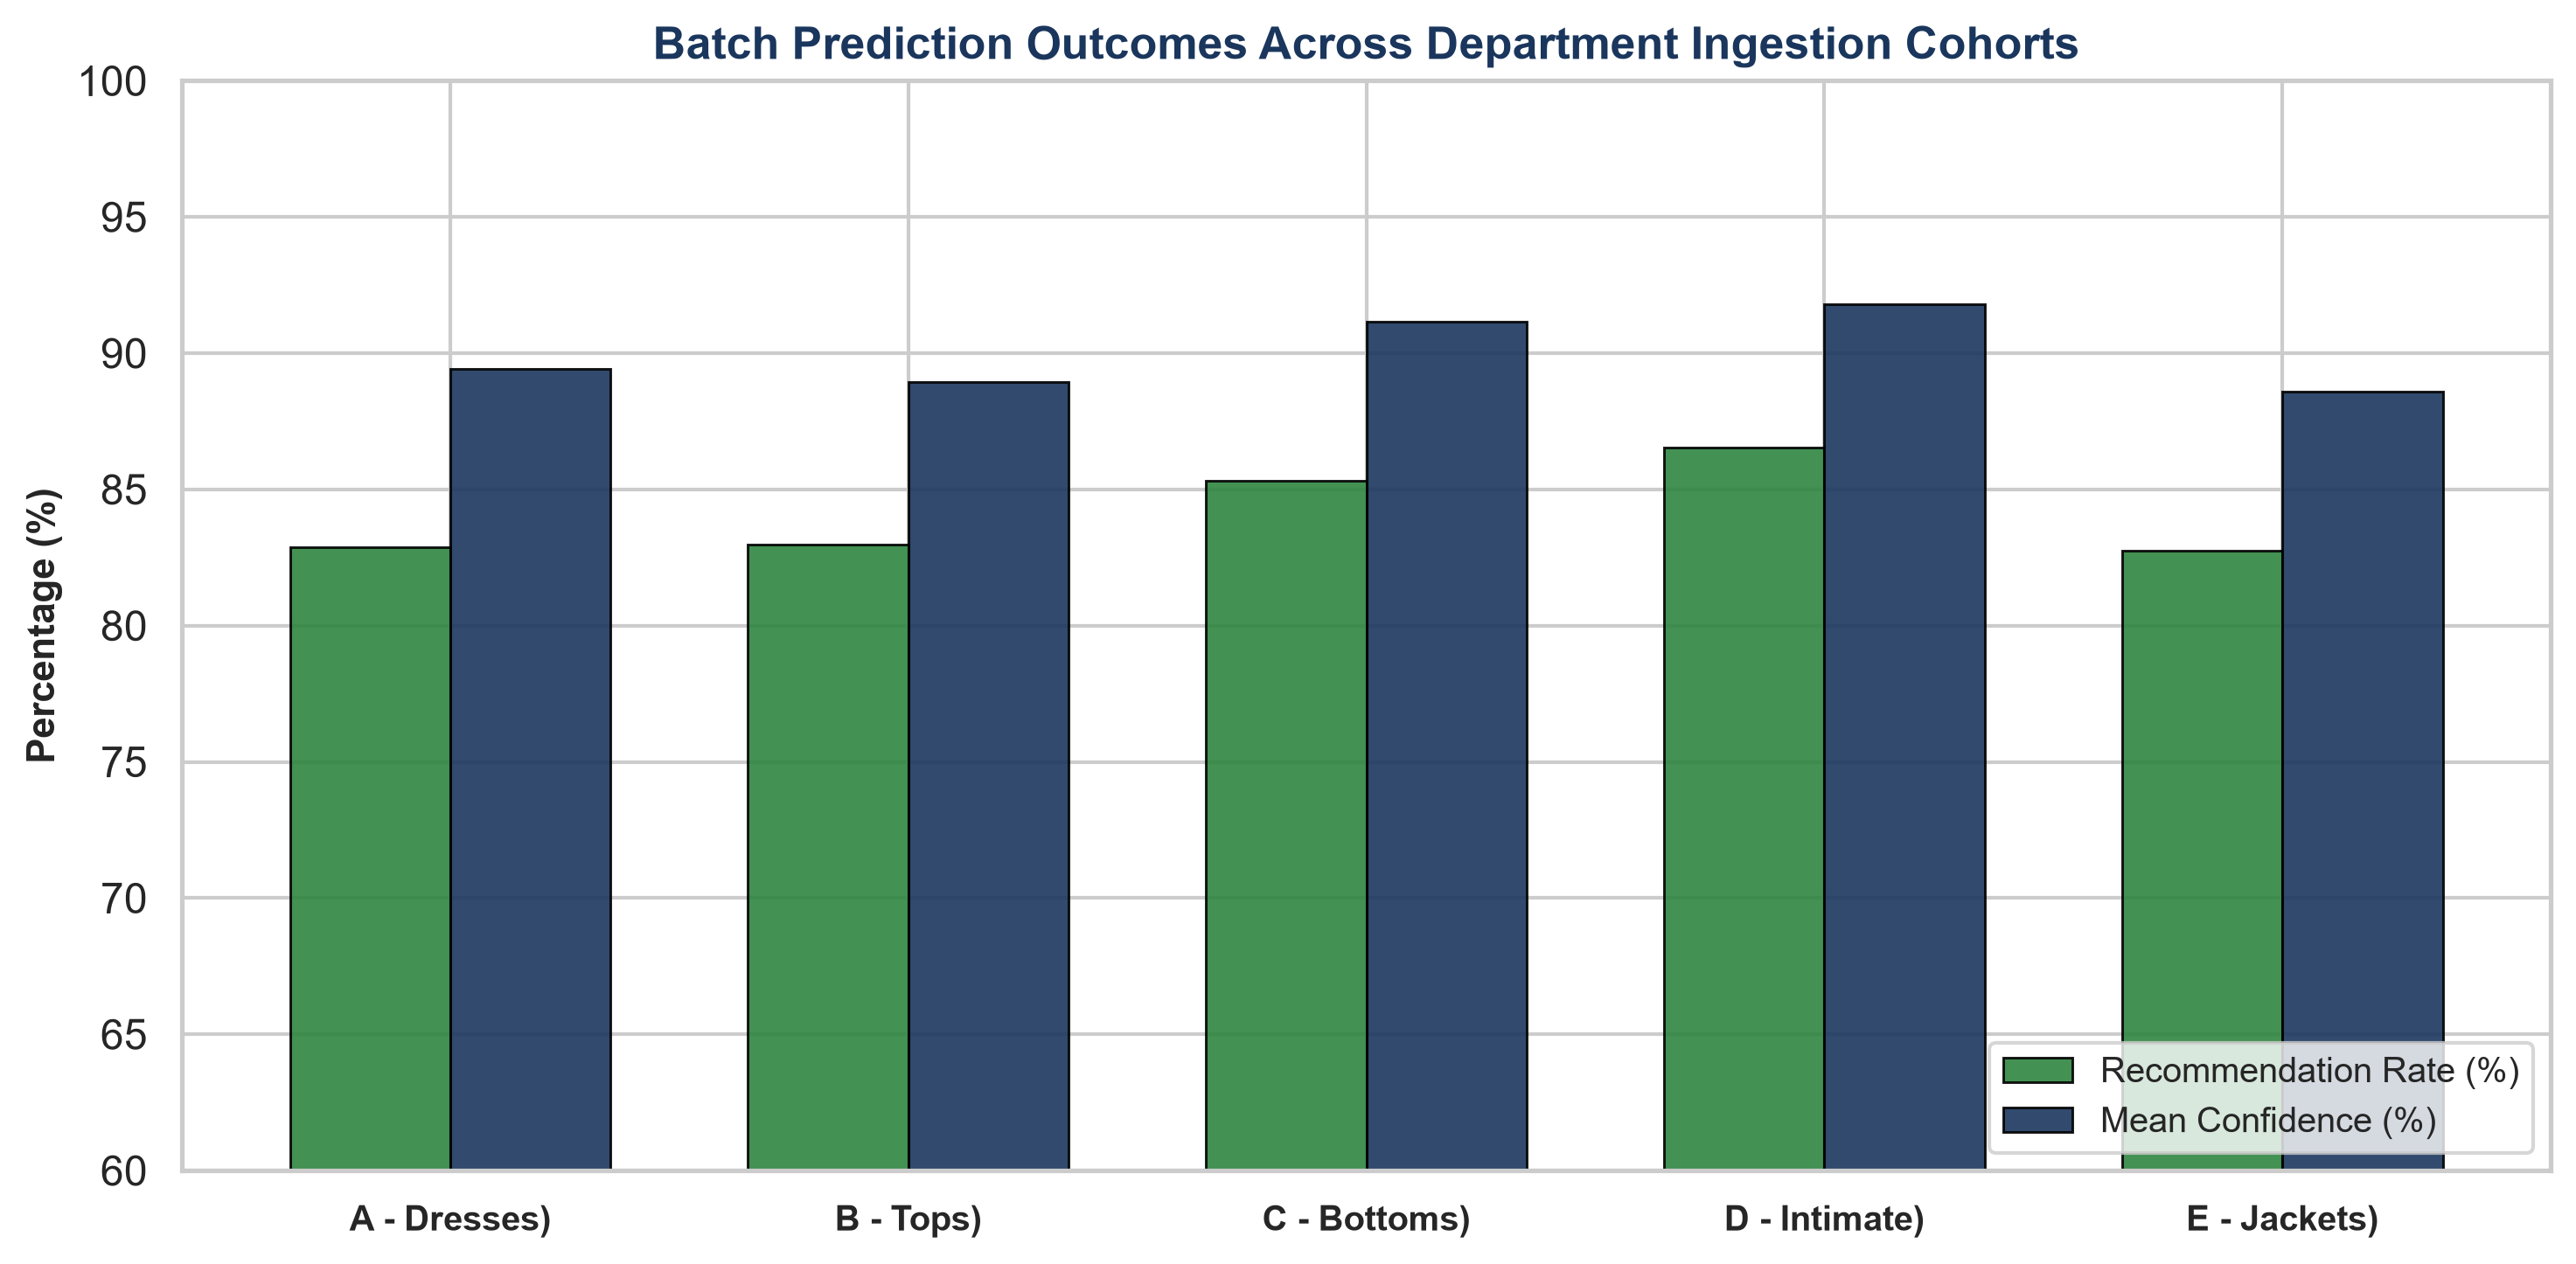

In [7]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
batch_names = df_batch['Batch_ID']
rec_rates = df_batch['Recommendation_Rate_Pct']
conf_rates = df_batch['Mean_Confidence_Pct']

x = np.arange(len(batch_names))
w = 0.35

ax.bar(x - w/2, rec_rates, w, label='Recommendation Rate (%)', color='#2E8540', alpha=0.9, edgecolor='black', linewidth=0.7)
ax.bar(x + w/2, conf_rates, w, label='Mean Confidence (%)', color='#1A365D', alpha=0.9, edgecolor='black', linewidth=0.7)

ax.set_title("Batch Prediction Outcomes Across Department Ingestion Cohorts", fontsize=12.5, fontweight='bold', color='#1A365D')
ax.set_ylabel("Percentage (%)", fontsize=10.5, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([b.replace('Batch_', '').replace(' (', ' - ') for b in batch_names], fontsize=9.5, fontweight='bold')
ax.set_ylim(60, 100)
ax.legend(loc='lower right', frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()